In [ ]:
import pandas as pd
import numpy as np


In [ ]:
df=pd.read_csv('A_Z Handwritten Data.csv')

In [ ]:
df

,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,0.639,0.640,0.641,0.642,0.643,0.644,0.645,0.646,0.647,0.648
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372445,25,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
372446,25,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
372447,25,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
372448,25,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372450 entries, 0 to 372449
Columns: 785 entries, 0 to 0.648
dtypes: int64(785)
memory usage: 2.2 GB


In [ ]:

csv_path = "A_Z Handwritten Data.csv"

# Count total rows
with open(csv_path, "r") as f:
    total_rows = sum(1 for _ in f)

# Randomly select 5000 row indices
rng = np.random.default_rng(42)

selected_rows = set(
    rng.choice(total_rows, size=5000, replace=False)
)

# Read only selected rows
df = pd.read_csv(
    csv_path,
    header=None,
    skiprows=lambda i: i not in selected_rows,
    dtype=np.uint8
)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

# First column contains labels (0-25)
y = df.iloc[:, 0].to_numpy().astype("int32")

# Remaining 784 columns contain image pixels
X = df.iloc[:, 1:].to_numpy().astype("float32")

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique labels:", np.unique(y))


Features shape: (5000, 784)
Labels shape: (5000,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]


In [ ]:

# Convert 784 pixels into 28x28 grayscale images
X = X.reshape(-1, 28, 28, 1)

# Normalize pixel values to 0-1
X = X / 255.0

print("Reshaped X:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Reshaped X: (5000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (4000, 28, 28, 1)
Testing: (1000, 28, 28, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense
)

In [ ]:

n_classes = 26

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation="relu"),
    Dense(n_classes, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         1,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,970 (480.35 KB)

 Trainable params: 122,970 (480.35 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.5472 - loss: 1.6956 - val_accuracy: 0.7788 - val_loss: 0.7647
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - accuracy: 0.8306 - loss: 0.5882 - val_accuracy: 0.8600 - val_loss: 0.4733
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.9016 - loss: 0.3513 - val_accuracy: 0.9100 - val_loss: 0.3438
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.9375 - loss: 0.2423 - val_accuracy: 0.9162 - val_loss: 0.3029
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9522 - loss: 0.1798 - val_accuracy: 0.9200 - val_loss: 0.3269


In [ ]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Accuracy: 89.50%


In [ ]:
import matplotlib.pyplot as plt


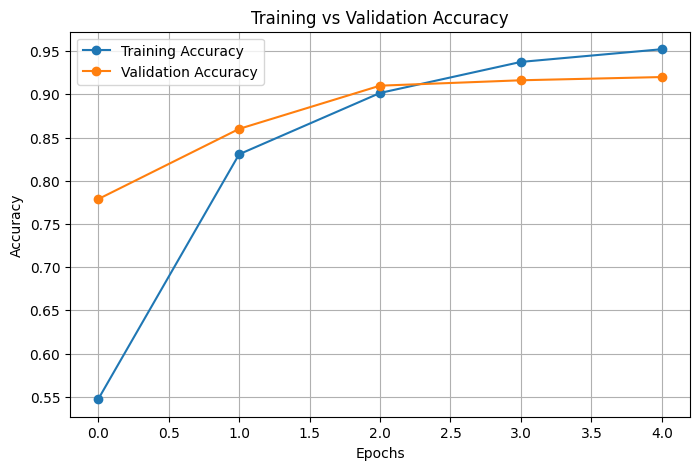

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


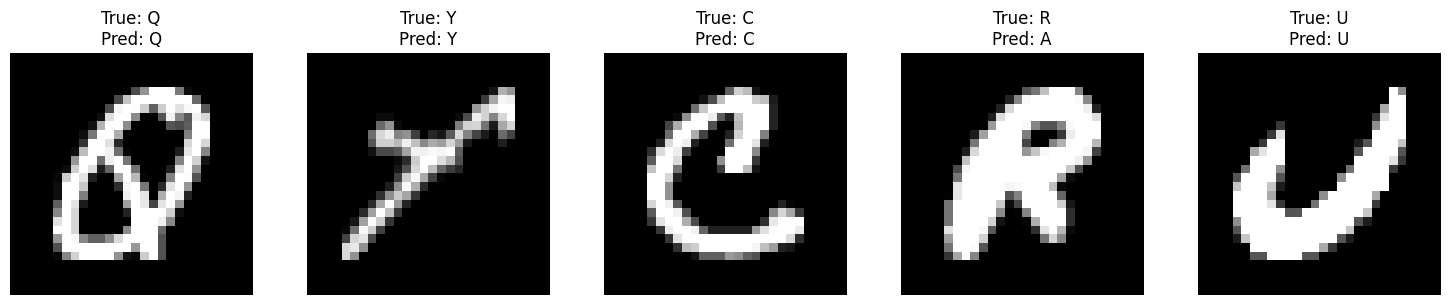

In [ ]:

# Predict test images
predictions = model.predict(X_test, verbose=0)

# Get predicted class labels
y_pred = np.argmax(predictions, axis=1)

# Select 5 random test images
indices = np.random.default_rng(42).choice(
    len(X_test), size=5, replace=False
)

plt.figure(figsize=(15, 3))

for i, idx in enumerate(indices):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    true_label = chr(65 + y_test[idx])
    predicted_label = chr(65 + y_pred[idx])

    plt.title(
        f"True: {true_label}\nPred: {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()
